# Visualization

## 1. Subtyping test

   Unnamed: 0  folds  test_auc   val_auc  test_acc   val_acc      group
0           0      0  0.991131  0.998148  0.896552  0.931034  subtyping
1           1      1  0.994542  0.986667  0.896552  0.900000  subtyping
2           2      2  0.946101  0.994347  0.793103  0.964286  subtyping
3           3      3  0.985673  0.988986  0.931034  0.896552  subtyping
4           4      4  1.000000  0.997917  0.928571  0.964286  subtyping


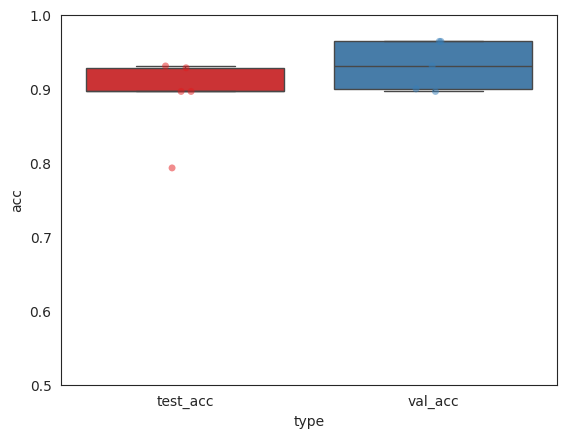

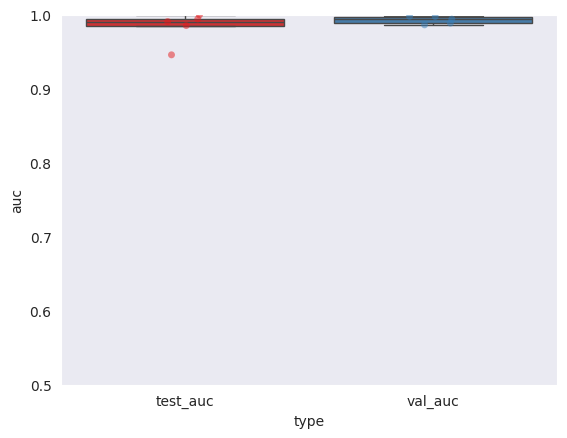

In [73]:
# By default from summary file

import pandas as pd
import numpy as np
import os 

import matplotlib.pyplot as plt
import seaborn as sns

summary_df = pd.read_csv(os.path.join('/mnt/central_nas/rcc_volume/RCC/HE/CLAM/subtyping_test/results/dry_run_s1/summary.csv'))
summary_df['group'] = 'subtyping'
print(summary_df.head())

## Acurracy
auc_viz = summary_df.melt(id_vars= 'folds', value_vars= ['test_acc', 'val_acc'], var_name= 'type', value_name= 'acc')

sns.set_style('white')
p = sns.boxplot(data=acc_viz, x='type', y='acc', hue='type', palette = 'Set1',showfliers=False)
p = sns.stripplot(data=acc_viz, x='type', y='acc', hue='type', palette = 'Set1', alpha=0.5)
p.set(ylim=(0.5,1))
plt.show()
plt.close()

## AUC
auc_viz = summary_df.melt(id_vars= 'folds', value_vars= ['test_auc', 'val_auc'], var_name= 'type', value_name= 'auc')

sns.set_style('white')
p = sns.boxplot(data=auc_viz, x='type', y='auc', hue='type', palette = 'Set1',showfliers=False)
p = sns.stripplot(data=auc_viz, x='type', y='auc', hue='type', palette = 'Set1', alpha=0.5)
p.set(ylim=(0.5,1))
plt.show()


In [89]:
# Custom reading in of results files 

import os
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import ConfusionMatrixDisplay

# Load results as pickle files
def load_results(files):
    results = []
    for file in files:
        with open(file, 'rb') as f:
            results.append(pickle.load(f))
    return results

pkl_files = ['/mnt/central_nas/rcc_volume/RCC/HE/CLAM/subtyping_test/results/dry_run_s1/split_0_results.pkl',
'/mnt/central_nas/rcc_volume/RCC/HE/CLAM/subtyping_test/results/dry_run_s1/split_1_results.pkl',
'/mnt/central_nas/rcc_volume/RCC/HE/CLAM/subtyping_test/results/dry_run_s1/split_2_results.pkl',
'/mnt/central_nas/rcc_volume/RCC/HE/CLAM/subtyping_test/results/dry_run_s1/split_3_results.pkl',
'/mnt/central_nas/rcc_volume/RCC/HE/CLAM/subtyping_test/results/dry_run_s1/split_4_results.pkl'] 

# Load all the results
results = load_results(pkl_files)


In [90]:
# Prepare lists to store performance metrics (F1 scores, etc.)
f1_scores_weighted = []
accuracy_scores = []
precision_scores = []
recall_scores = []
confusion_matrices = []

# Loop through the results of each fold
for result in results:
    true_labels = []
    pred_labels = []
    for key, value in result.items():
        true_labels.append(value['label'])
        pred_labels.append(np.argmax(value['prob'], axis=1))  # predicted class
    
    # Convert lists to numpy arrays
    true_labels = np.array(true_labels)
    pred_labels = np.array(pred_labels)
    
    # Calculate the confusion matrix for the current fold
    cm = confusion_matrix(true_labels, pred_labels)
    confusion_matrices.append(cm)
    
    # Compute accuracy, precision, recall, and F1 scores
    accuracy_scores.append(accuracy_score(true_labels, pred_labels))
    precision_scores.append(precision_score(true_labels, pred_labels, average='weighted'))
    recall_scores.append(recall_score(true_labels, pred_labels, average='weighted'))
    
    # Calculate the weighted F1 score and append it to the list
    weighted_f1 = f1_score(true_labels, pred_labels, average='weighted')
    f1_scores_weighted.append(weighted_f1)

# Visualize performance scores across folds
metrics_df = pd.DataFrame({
    'Accuracy': accuracy_scores,
    'Precision (weighted)': precision_scores,
    'Recall (weighted)': recall_scores,
    'F1 Score (weighted)': f1_scores_weighted
})

metrics_df.head()

,Accuracy,Precision (weighted),Recall (weighted),F1 Score (weighted)
0,0.896552,0.904215,0.896552,0.895950
1,0.896552,0.920424,0.896552,0.898081
2,0.793103,0.815271,0.793103,0.788793
3,0.931034,0.943574,0.931034,0.930651
4,0.928571,0.935390,0.928571,0.925897


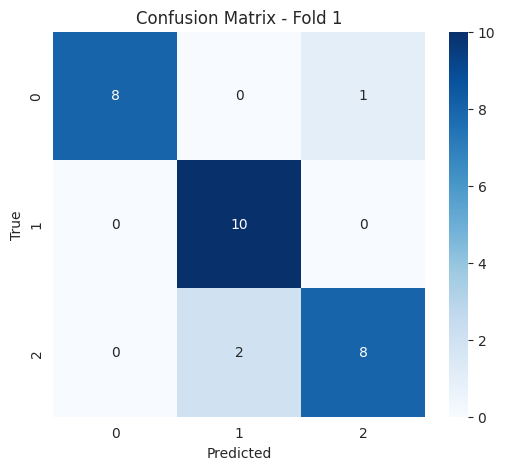

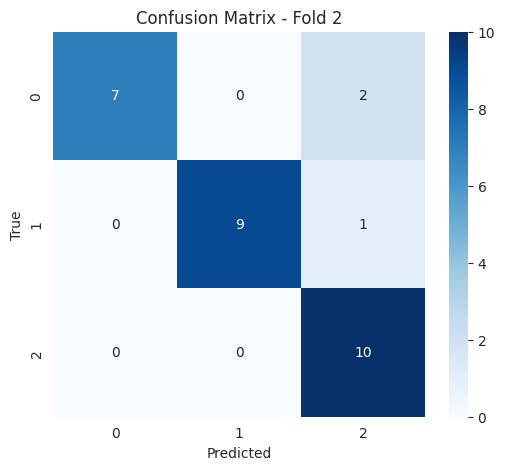

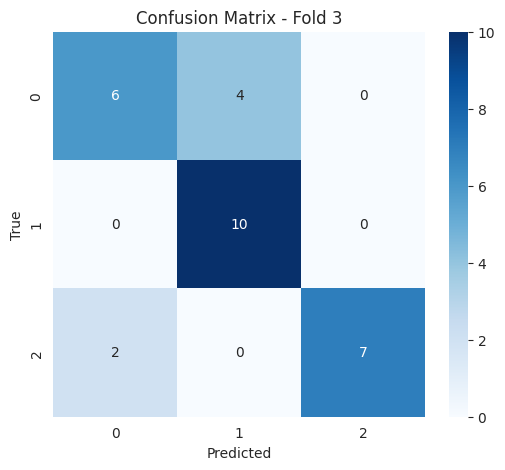

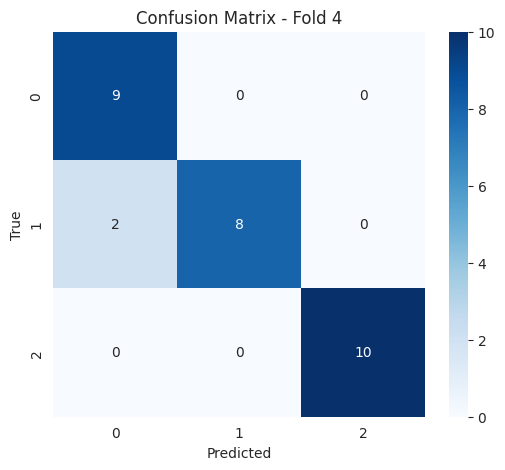

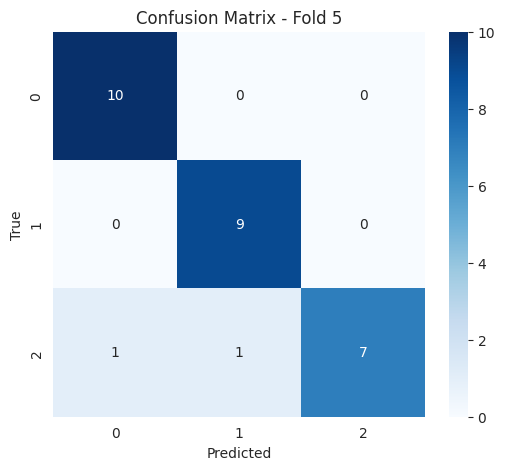

In [91]:
# Visualize Confusion Matrix for each fold
for i, cm in enumerate(confusion_matrices):
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1, 2], yticklabels=[0, 1, 2])
    plt.title(f'Confusion Matrix - Fold {i + 1}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

/tmp/ipykernel_2820425/1470613953.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=f1_scores_weighted, palette='Paired',showfliers=False)


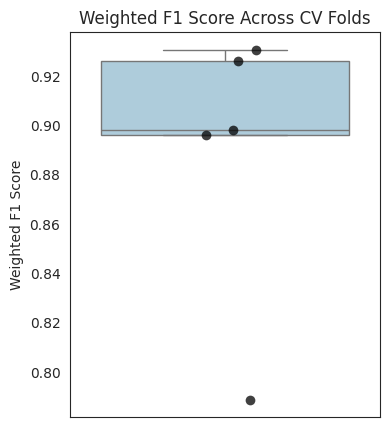

In [103]:
# Plot the boxplot for weighted F1 scores
sns.set_style('white')
plt.figure(figsize=(4, 5))
sns.boxplot(data=f1_scores_weighted, palette='Paired',showfliers=False)
sns.stripplot(data=f1_scores_weighted, color='black', alpha = 0.75, size=7)
plt.title('Weighted F1 Score Across CV Folds')
plt.ylabel('Weighted F1 Score')
plt.show()

Notes: These performance metrics are currently estimated on a slide-level and not patient-level. TO DO: Also have code for patient-level.